In [1]:
import time

import numpy as np

import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml

from sklearn.model_selection import train_test_split

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import accuracy_score

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
# ---------------------------------------------------------

# 1. Load MNIST Dataset

# ---------------------------------------------------------

print("Loading MNIST dataset...")

X, y = fetch_openml(

    'mnist_784',

    version=1,

    return_X_y=True,

    as_frame=False

)

# Convert data to numeric

X = X.astype('float32')

y = y.astype('int')

print("Dataset loaded successfully!")

print("Total samples:", X.shape[0])

print("Number of features:", X.shape[1])

Loading MNIST dataset...
Dataset loaded successfully!
Total samples: 70000
Number of features: 784


In [ ]:
# ---------------------------------------------------------

# 2. Preprocess the Dataset

# ---------------------------------------------------------

# Normalize pixel values from 0-255 to 0-1

X = X / 255.0

# Use a smaller subset for faster execution

X = X[:20000]

y = y[:20000]

# Split into training and testing data

X_train, X_test, y_train, y_test = train_test_split(

    X, y,

    test_size=0.2,

    random_state=42,

    stratify=y

)

print("\nTraining samples:", X_train.shape[0])

print("Testing samples:", X_test.shape[0])


Training samples: 16000
Testing samples: 4000


In [ ]:
# ---------------------------------------------------------

# 3. Define Activation Functions

# ---------------------------------------------------------

activations = ['logistic', 'relu', 'tanh']

results = {}

training_times = {}

accuracies = {}

In [ ]:
# ---------------------------------------------------------

# 4. Train Neural Network with Each Activation Function

# ---------------------------------------------------------

for activation in activations:

    print("\n----------------------------------")

    print("Training with:", activation)

    print("----------------------------------")

    start_time = time.time()

    model = MLPClassifier(

        hidden_layer_sizes=(128,),

        activation=activation,

        solver='adam',

        max_iter=100,

        batch_size=128,

        random_state=42,

        verbose=False

    )

    model.fit(X_train, y_train)

    end_time = time.time()

    # Calculate training time

    training_time = end_time - start_time

    # Prediction

    y_pred = model.predict(X_test)

    # Accuracy

    accuracy = accuracy_score(y_test, y_pred)

    # Store results

    results[activation] = model

    training_times[activation] = training_time

    accuracies[activation] = accuracy * 100

    print("Training time: {:.2f} seconds".format(training_time))

    print("Number of iterations:", model.n_iter_)

    print("Test accuracy: {:.2f}%".format(accuracy * 100))


----------------------------------
Training with: logistic
----------------------------------
Training time: 15.58 seconds
Number of iterations: 99
Test accuracy: 95.58%

----------------------------------
Training with: relu
----------------------------------
Training time: 9.63 seconds
Number of iterations: 57
Test accuracy: 96.08%

----------------------------------
Training with: tanh
----------------------------------
Training time: 10.40 seconds
Number of iterations: 61
Test accuracy: 95.80%


In [ ]:
# ---------------------------------------------------------

# 5. Display Comparison Table

# ---------------------------------------------------------

print("\n==========================================")

print("       ACTIVATION FUNCTION COMPARISON")

print("==========================================")

print("{:<12} {:<15} {:<15} {:<15}".format(

    "Activation", "Time (sec)", "Iterations", "Accuracy (%)"

))

for activation in activations:

    model = results[activation]

    print("{:<12} {:<15.2f} {:<15} {:<15.2f}".format(

        activation,

        training_times[activation],

        model.n_iter_,

        accuracies[activation]

    ))


       ACTIVATION FUNCTION COMPARISON
Activation   Time (sec)      Iterations      Accuracy (%)   
logistic     20.67           99              95.58          
relu         11.97           57              96.08          
tanh         10.05           61              95.80          


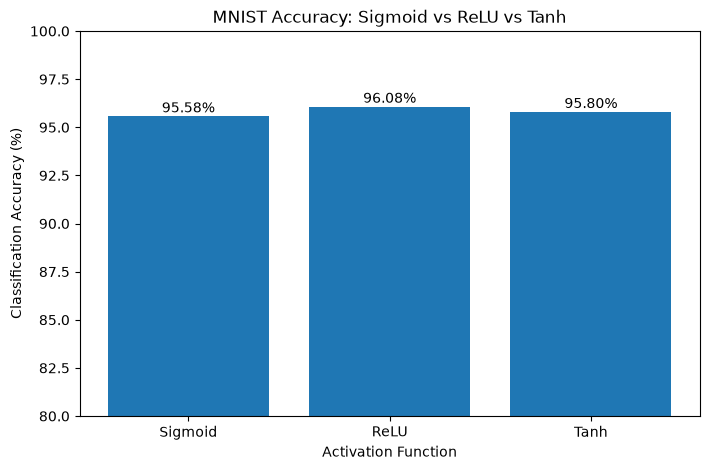

In [ ]:
# ---------------------------------------------------------

# 6. Accuracy Comparison Graph

# ---------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(

    ['Sigmoid', 'ReLU', 'Tanh'],

    [

        accuracies['logistic'],

        accuracies['relu'],

        accuracies['tanh']

    ]

)

plt.xlabel("Activation Function")

plt.ylabel("Classification Accuracy (%)")

plt.title("MNIST Accuracy: Sigmoid vs ReLU vs Tanh")

plt.ylim(80, 100)

# Display accuracy values

for i, value in enumerate([

    accuracies['logistic'],

    accuracies['relu'],

    accuracies['tanh']

]):

    plt.text(i, value + 0.2, f"{value:.2f}%",

             ha='center')

plt.show()

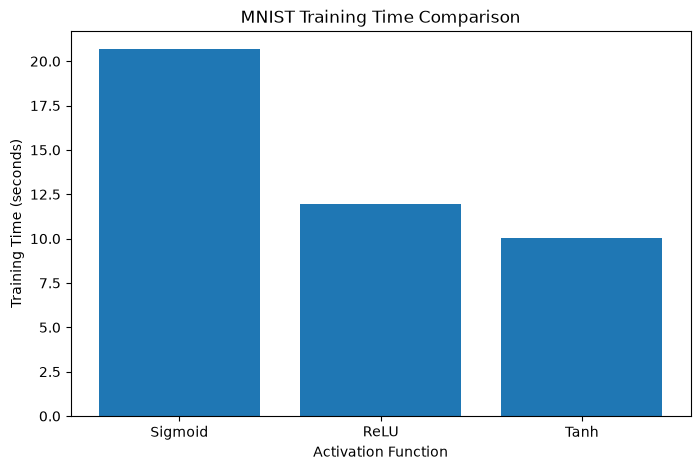

In [ ]:


# ---------------------------------------------------------

# 7. Training Time Comparison Graph

# ---------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(

    ['Sigmoid', 'ReLU', 'Tanh'],

    [

        training_times['logistic'],

        training_times['relu'],

        training_times['tanh']

    ]

)

plt.xlabel("Activation Function")

plt.ylabel("Training Time (seconds)")

plt.title("MNIST Training Time Comparison")

plt.show()

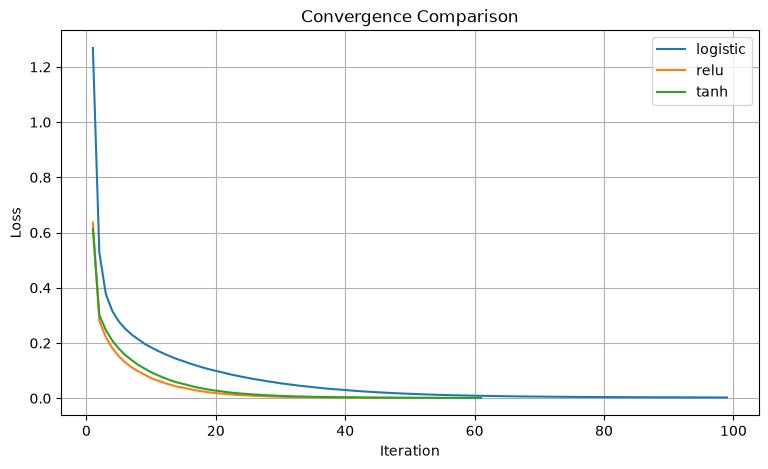

In [ ]:
# ---------------------------------------------------------

# 8. Convergence Comparison

# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

for activation in activations:

    model = results[activation]

    plt.plot(

        range(1, len(model.loss_curve_) + 1),

        model.loss_curve_,

        label=activation

    )

plt.xlabel("Iteration")

plt.ylabel("Loss")

plt.title("Convergence Comparison")

plt.legend()

plt.grid(True)

plt.show()